In [17]:
import numpy as np
import matplotlib.pyplot as plt
import os
import astropy.units as u
import json

import matplotlib.colors as mcolors
import matplotlib.cm as cm
from mpl_toolkits.axes_grid1 import make_axes_locatable

from transform_data import get_transformed_data

import flash_amr_tools
import h5py

In [18]:
fig_dir = "/home/kwatanabe/Projects/cr-bowshocks/figures/emission_revised/"
# flash_output_dir = "/home/kwatanabe/Projects/cr-bowshocks/outputs_new/ISM_v30_CR"
# flash_output_dir = "/home/kwatanabe/Projects/cr-bowshocks/FlashISM/runs/BowShock_CR_new_v100"

flash_output_dir = "/home/kwatanabe/Projects/cr-bowshocks/updated_outputs/ISM-v40-MDiff"
# flash_output_dir = "/home/kwatanabe/Projects/cr-bowshocks"

# load the bowshock config
bowshock_config = json.load(open("../../config/bowshock_config.json", "r"))["config"]

In [19]:
times_to_plot = np.array([500])
sim_ids = (times_to_plot // 20).astype(int)
synch_freq = 1.5 # in GHz

In [20]:
def load_file_contents(sim_file, emission_file):
    blist, brefs, bns = flash_amr_tools.get_true_blocks(sim_file)

    pf = h5py.File(sim_file)
    ref_lvl = pf["refine level"][()][blist]
    bbox = pf["bounding box"][()][blist]
    bsize = pf["block size"][()][blist]
    time = (pf['real scalars'][()][0][1] * u.s).to(u.kyr)
    print(time)

    low_cor, up_cor = bbox[0,:,0], bbox[-1,:,1]
    # extent for imshow
    extent = ([low_cor[0], up_cor[0], low_cor[1], up_cor[1]] * u.cm).to_value(u.pc)

    pf.close()

    # read in the emission data file
    emission_hdf5 = h5py.File(emission_file, "r")

    # wrap reader parameters in dictionary
    reader_params = {
        "brefs": brefs,
        "bns": bns,
        "ref_lvl": ref_lvl,
        "bbox": bbox,
        "bsize": bsize,
    }

    return emission_hdf5, reader_params, blist, extent, time

In [21]:
field_lims = {
    'ncr_p' : [1e-15, 1e-9],
    'ncr_e' : [1e-13, 1e-5],
    'ncre_synch' : [1e-10, 1e-5],
    'synch_intensity' : [1e-40, 1e-30]
}

field_cmaps = {
    'ncr_p' : cm.viridis,
    'ncr_e' : cm.viridis,
    'ncre_synch' : cm.inferno,
    'synch_intensity' : cm.inferno,
    'ecr_p_val' : cm.viridis
}

field_labels = {
    'ncr_p' : r'$n_{\mathrm{CR}, p}$ / cm$^{-3}$',
    'ncr_e' : r'$n_{\mathrm{CR}, e}$ / cm$^{-3}$',
    'ncre_synch' : r'$n_{\mathrm{CR}, e, synch}$ / cm$^{-3}$',
    'synch_intensity' : r'Synchrotron Intensity / erg s$^{-1}$ cm$^{-2}$ Hz$^{-1}$ sr$^{-1}$'
}

minimum position of the region of interest:  [-1.54283879e+20 -7.71419300e+19 -7.71419300e+19]
maximum position of the region of interest:  [1.54283879e+20 7.71419300e+19 7.71419300e+19]
Finding all leaf blocks in given region
20463 20463
Biggest block has refinement level: 4
Highest refinement level in simulation: 6
Highest refinement level in selected box: 6
Extending region to fit amr structure at level 4.
Trying extended region given by including blocks whose center is not in predefined region but part of their block volume is.
bnx, bny, bnz:  16.0 8.0 8.0
Block shape:  (16, 8, 8)
Total number of blocks including parent blocks: 23240
Region extended to:	lower		upper
	x	-1.54283894e+20		+1.54283876e+20
	y	-7.71419293e+19		+7.71419293e+19
	z	-7.71419293e+19		+7.71419293e+19

Region center at:	-8.79609302e+12	+0.00000000e+00	+0.00000000e+00
Given center:		+0.00000000e+00	+0.00000000e+00	+0.00000000e+00
500.0042804520129 kyr
<KeysViewHDF5 ['b_adiab', 'b_coul', 'b_coul_e', 'b_hadr', 'b_

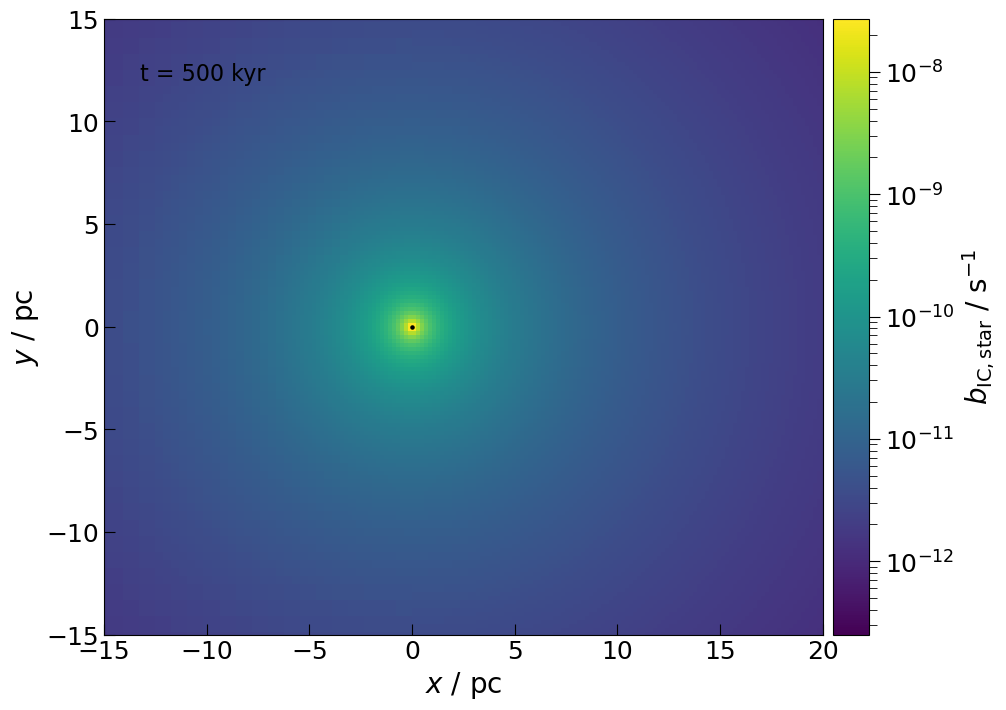

In [22]:
# fields = ['ncr_p', 'ncr_e',]
fields = ['b_ic_star']
# fields = ['geff']

for it, t in enumerate(times_to_plot):
    sim_dir = os.path.join(flash_output_dir)
    emission_file = os.path.join(sim_dir, f"emission_data_t{t:.0f}.h5")
    sim_file = os.path.join(sim_dir, f"starISM_hdf5_plt_cnt_{sim_ids[it]:04d}")

    emission_hdf5, reader_params, blist, extent, time = load_file_contents(sim_file, emission_file)
    print(emission_hdf5.keys())

    # emission_hdf5.close()
    # break

    for ifield, field in enumerate(fields):

        if field.startswith('synch_intensity') or field.startswith('ncre_synch'):
            field_hdf5_label = f'{field}_{synch_freq:.2f}GHz'
        else:
            field_hdf5_label = field

        field_data = np.abs(emission_hdf5[field_hdf5_label][()])
        field_slice = flash_amr_tools.get_slice(field_data, pos=0.0, axis=2, **reader_params)

        print(f'field : {field_hdf5_label}, min : {np.min(field_slice)}, max : {np.max(field_slice):.2e}')

        # norm = mcolors.LogNorm(vmin=field_lims[field][0], vmax=field_lims[field][1], clip=True)
        # cmap = field_cmaps[field]
        norm = mcolors.LogNorm(vmin=np.min(field_slice[field_slice>0]), vmax=np.max(field_slice), clip=True)
        cmap = cm.viridis

        fig, ax = plt.subplots(figsize=(15,8))

        im = ax.imshow(field_slice.T, norm=norm, cmap=cmap, origin="lower", extent=extent)
        ax.scatter(0, 0, s=5.0, color="k")

            # labels
        ax.set_xlabel("$x$ / pc", fontsize=20)
        ax.set_ylabel("$y$ / pc", fontsize=20)
        # ticks
        ax.tick_params(axis='both', direction="in", which='major', size=8, labelsize=18)
        ax.tick_params(axis='both', direction="in", which='minor', size=6, labelsize=16)

        ax.set_xlim(-15, 20)
        ax.set_ylim(-15, 15)

        # colorbar
        # make separate axes for each image
        divider = make_axes_locatable(ax)
        cax = divider.append_axes("right", size="5%", pad=0.1)

        # set ticks as text for shck
        cb = fig.colorbar(im, ax=ax, cax=cax)
        # cb.ax.set_ylabel(field_labels[field], fontsize=20)
        # cb.ax.set_ylabel(field_hdf5_label, fontsize=20)
        cb.ax.set_ylabel(r"$b_{\mathrm{IC, star}}$ / s$^{-1}$", fontsize=20)
        cb.ax.tick_params(axis='both', which='major', size=8, labelsize=18)
        cb.ax.tick_params(axis='both', which='minor', size=6, labelsize=18)

        # scales
        cb.ax.set_yscale('log')

        ax.annotate(f"t = {time:.0f}", xy=(0.05, 0.90), xycoords='axes fraction', color='k', fontsize=16)

        fig.savefig(os.path.join(fig_dir, f"{field_hdf5_label}_slice_t{t:.0f}.png"), bbox_inches='tight', dpi=300)

    emission_hdf5.close()